# Exercise 4.3 | Model Assumptions

Our test results are only valid when the model assumptions are valid. We'll diagnose the happiness and GDP model from Exercise 4.1 by checking each assumption with the model's **residuals** and **predictions**:

1. **Linearity**: the relationship between $x$ and $y$ is linear
2. **Homoskedasticity**: equal error variance across all values of $x$
3. **Independence**: observations are independent from each other
4. **Normality**: errors are normally distributed

Complete the notebook, then enter your answers in Gradescope.

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# File Path
file_path = 'https://econ-0150.tayweid.io/data/'

In [2]:
# Load Data
data = pd.read_csv(file_path + 'Life_Evaluation_GDP_PerCap.csv')
# Log10 of GDP per capita
data['log_GDP_PerCap'] = np.log10(data['GDP_Per_Cap'])
# Keep 2024
data = data[data['Year'] == 2024]
# Display header
data.head()

,Year,Country,Life_Evaluation,GDP_Per_Cap,log_GDP_PerCap
0,2024,Afghanistan,1.364,549.27,2.739786
13,2024,Albania,5.411,5411.94,3.733353
26,2024,Algeria,5.571,4361.21,3.639607
45,2024,Argentina,6.397,11107.35,4.045610
58,2024,Armenia,5.494,5016.99,3.700443


## General Linear Model

**Question 1.** Fit the model from Exercise 4.1 and print the coefficient table.

$$LifeEvaluation_i = \beta_0 + \beta_1 \cdot logGDP_i + \epsilon_i$$

*Hint: save `smf.ols('Life_Evaluation ~ log_GDP_PerCap', data=data).fit()` as `model`, then use `print(model.summary().tables[1])`.*

In [3]:
# Model: y = b + mx
model = smf.ols('Life_Evaluation ~ log_GDP_PerCap', data=data).fit() # Intercept is included by default
print(model.summary().tables[1])

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -0.2502      0.364     -0.687      0.493      -0.970       0.469
log_GDP_PerCap     1.5145      0.093     16.225      0.000       1.330       1.699


## Residuals

**Question 2.** Calculate the model's residuals and predictions.

*Hint: save `model.resid` as `residuals` and `model.predict()` as `predictions`.*

In [4]:
# Calculate residuals and predictions
residuals = model.resid
predictions = model.predict()

## Assumptions 1 and 2: Residual Plot

**Question 3.** Make a residual plot: predictions against residuals. Is there a curve in the residuals (linearity)? Is their spread about the same everywhere (homoskedasticity)?

*Hint: `plt.scatter(predictions, residuals)`.*

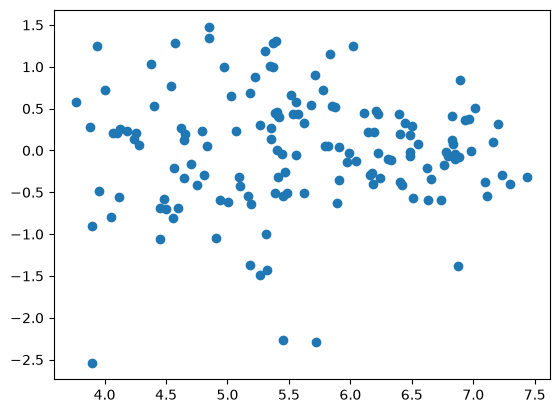

In [5]:
# Residual Plot: predictions against residuals
plt.scatter(predictions, residuals)

No: the residuals scatter around zero across the whole range of predictions

Roughly, though the residuals are somewhat less spread out at the highest predictions

## Assumption 3: Lagged Residual Plot

**Question 4.** Make a lagged residual plot: each residual against the residual of the row before it. Do you see a pattern?

*Hint: save `residuals[:-1]` as `lagged_residuals` and `residuals[1:]` as `current_residuals`, then use `plt.scatter(lagged_residuals, current_residuals)`.*

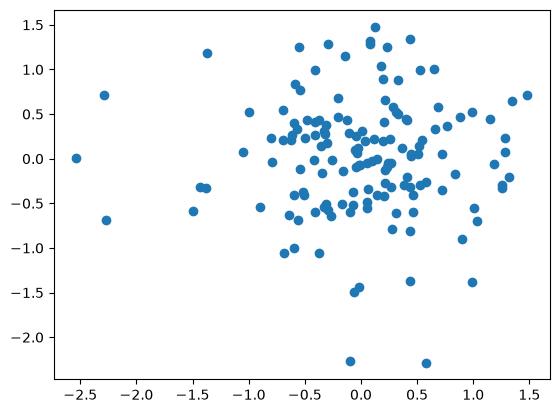

In [6]:
# Create lagged residuals
lagged_residuals = residuals[:-1]
current_residuals = residuals[1:]

# Lag plot
plt.scatter(lagged_residuals, current_residuals)

No pattern: a residual tells us nothing about the residual of the row before it

## Assumption 4: Normality of Residuals

**Question 5.** Make a histogram of the residuals. Are they roughly normally distributed?

*Hint: `sns.histplot(residuals, kde=True)`.*

<Axes: ylabel='Count'>

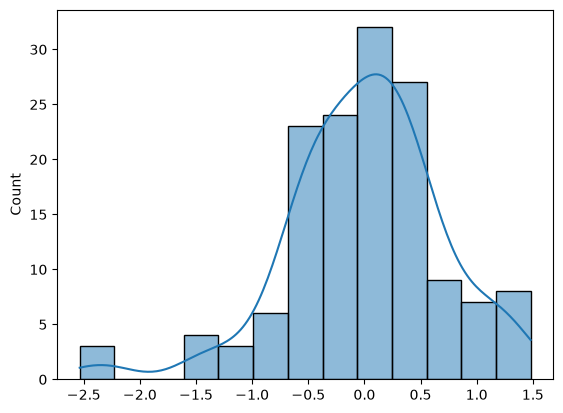

In [7]:
sns.histplot(residuals, kde=True)

Roughly bell-shaped and centered at zero, with a longer left tail from a few countries far below the line